<a href="https://colab.research.google.com/github/scottaudrey/svd-food-recommendation-system/blob/main/notebooks/01_ratings_matrix.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [44]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [45]:
foods = ["Sweet 1", "Sweet 2", "Sweet 3",
          "Savory 1", "Savory 2", "Savory 3"]
users = ["John", "Ben", "Jake", "Princeton", "Eve", "Fay"]

In [46]:
ratings = np.array([
[5, 4, 5, 1, np.nan, 2], # John
[4, np.nan, 5, 2, 1, 1], # Ben
[5, 5, np.nan, 1, 2, np.nan], # Jake
[1, 2, 1, 5, 4, np.nan], # Princeton
[np.nan, 1, 2, 4, 5, 5], # Eve
[2, 1, np.nan, 5, np.nan, 4], # Fay
])

In [47]:
ratings_table = pd.DataFrame(ratings, index=users, columns=foods)
ratings_table

,Sweet 1,Sweet 2,Sweet 3,Savory 1,Savory 2,Savory 3
John,5.0,4.0,5.0,1.0,NaN,2.0
Ben,4.0,NaN,5.0,2.0,1.0,1.0
Jake,5.0,5.0,NaN,1.0,2.0,NaN
Princeton,1.0,2.0,1.0,5.0,4.0,NaN
Eve,NaN,1.0,2.0,4.0,5.0,5.0
Fay,2.0,1.0,NaN,5.0,NaN,4.0


In [48]:
missing = np.isnan(ratings).sum()
print("Missing entries:", missing, "out of", ratings.size)

Missing entries: 8 out of 36


## Part B: The Amazon Food Review Data

In [49]:
import urllib.request
import zipfile

url = "https://github.com/ryannewhouse11/FoodReviewData/releases/latest/download/recipereview.zip"
urllib.request.urlretrieve(url, "/content/recipereview.zip")

with zipfile.ZipFile("/content/recipereview.zip") as z:
  csv_files = [
      name for name in z.namelist()
      if name.lower().endswith(".csv") and not name.startswith("_MACOSX/")
  ]
  print("CSV files:", csv_files)

  with z.open(csv_files[0]) as f:
    ratings = pd.read_csv(
        f,
        sep=",",
        header=0,
        names=["num_records", "recipe_number", "recipe_code", "recipe_name",
               "comment_id", "user_id", "user_name", "user_reputation", "created_at",
               "reply_count", "thumbs_up", "thumbs_down", "stars", "best_score", "text"]
    )



CSV files: ['Recipe Reviews and User Feedback Dataset.csv']


In [50]:
print("Number of ratings:", len(ratings))
print("Number of users:", ratings["user_id"].nunique())
print("Number of recipies:", ratings["recipe_code"].nunique())

Number of ratings: 18182
Number of users: 13812
Number of recipies: 100


In [51]:
ratings["stars"] = pd.to_numeric(ratings["stars"], errors='coerce')
star_counts = ratings["stars"].value_counts().sort_index()
star_counts

average_rating = ratings["stars"].mean()
print("Average rating:", round(average_rating, 3))

Average rating: 4.289


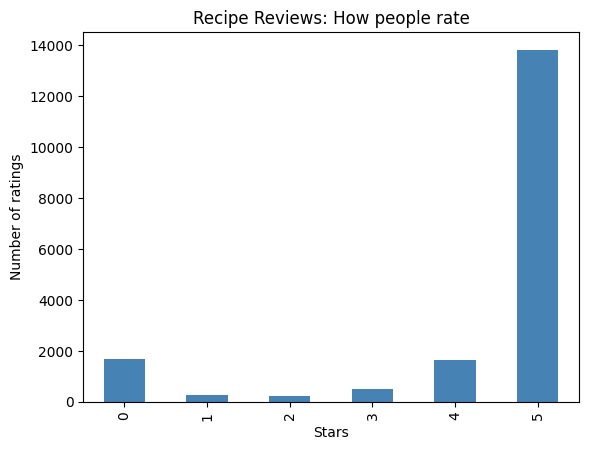

In [52]:
star_counts.plot(kind="bar", color="steelblue")
plt.xlabel("Stars")
plt.ylabel("Number of ratings")
plt.title("Recipe Reviews: How people rate")
plt.show()

## Part C: Building the user-by-food matrix

In [53]:
assert isinstance(ratings, pd.DataFrame), "Run Part B first: `ratings` must be the food ratings DataFrame"
required = {"user_id", "recipe_code", "stars"}
missing_cols = required - set(ratings.columns)
assert not missing_cols, f"`ratings` is missing columns: {missing_cols}"

In [54]:
n_users = ratings["user_id"].nunique()
n_foods = ratings["recipe_code"].nunique()
print("Matrix would be", n_users, "x", n_foods, "=", n_users * n_foods, "cells")

MAX_CELLS = 20_000_000
min_ratings = 20

if n_users * n_foods > MAX_CELLS:
    food_counts = ratings["recipe_code"].value_counts()
    user_counts = ratings["user_id"].value_counts()
    ratings = ratings[
        ratings["recipe_code"].isin(food_counts[food_counts >= min_ratings].index) &
        ratings["user_id"].isin(user_counts[user_counts >= min_ratings].index)
    ]
    n_users = ratings["user_id"].nunique()
    n_foods = ratings["recipe_code"].nunique()
    print("After filtering:", n_users, "x", n_foods, "=", n_users * n_foods, "cells")

Matrix would be 13812 x 100 = 1381200 cells


In [55]:
R = ratings.pivot_table(
    index="user_id",
    columns="recipe_code",
    values="stars"
)

In [56]:
print("Matrix shape:", R.shape)
fraction_missing = R.isna().to_numpy().mean()
print("Fraction missing:", round(fraction_missing, 4))

Matrix shape: (13812, 100)
Fraction missing: 0.9874


In [57]:
per_user = ratings.groupby("user_id").size()
print("Least active user:", per_user.min())
print("Median user:", int(per_user.median()))
print("Most active user:", per_user.max())

Least active user: 1
Median user: 1
Most active user: 25


In [58]:
print("Every rating in R:", R.notna().sum().sum() == len(ratings))
print(R.notna().sum().sum())
print(len(ratings))

Every rating in R: False
17393
18182


## Part D: Which Foods are Rated Most

In [59]:
recipies = ratings[["recipe_code", "recipe_name"]].drop_duplicates()

In [60]:
stats = ratings.groupby("recipe_code")["stars"].agg(["count", "mean"])
stats = stats.join(recipies.set_index("recipe_code"))

top_five = stats.sort_values("count", ascending=False).head(5)
top_five.round(2)

,count,mean,recipe_name
recipe_code,,,
2832,725,4.58,Cheeseburger Soup
14299,654,4.45,Creamy White Chili
3309,509,4.59,Best Ever Banana Bread
42083,421,4.10,Enchilada Casser-Ole!
32480,397,3.89,Basic Homemade Bread


## Exercises

In [61]:
# 1. In the toy matrix, identify all eight missing entries by user and movie. Give a predicted raating for each and justify two of your predictions using similar users or similar movies.
# (John, Savory2) - 1.0: All of John's ratings for savory foods are low, so it makes sense that savory 2 would also be low.
# (Ben, Sweet2) - 5.0: All of Ben's ratings for sweet foods are high, so it makes sense that sweet 2 would also be high.
# (Jake, Sweet3) - 5.0, (Jake, Savory3) - 2.0, (Prinction, Savory3) - 4.0,
# (Eve, Sweet1) - 1.0, (Fay, Sweet3) - 2.0, (Fay, Savory2) - 5.0

In [62]:
# 2. Add a seventh imaginary use who likes sweet foods and dislikes savory foods. Choose at least four ratings for this user, include two missing ratings, and explain what you would predict for them.
#                [Sweet1, Sweet2, Sweet3, Savory1, Savory2, Savory3]
# Imaginary User:  5.0      NaN     4.0     2.0     1.0        NaN
# Predictions: Sweet2 - 5.0, Savory3 - 1.0

In [65]:
toy = np.array([
[5, 4, 5, 1, np.nan, 2], # John
[4, np.nan, 5, 2, 1, 1], # Ben
[5, 5, np.nan, 1, 2, np.nan], # Jake
[1, 2, 1, 5, 4, np.nan], # Princeton
[np.nan, 1, 2, 4, 5, 5], # Eve
[2, 1, np.nan, 5, np.nan, 4], # Fay
])

In [72]:
from fractions import Fraction

In [79]:
# 3. What does the command np.isnan(toy).sum compute? Write a different line of code that computes the fraction of missing of missing entires in toy.
#  The command computes the total number of missing ratings in the toy (in our case, ratings) array
num = np.isnan(toy).sum()
solution = Fraction(np.isnan(toy).sum()/36.0).limit_denominator()
print(num)
print(solution)

8
2/9


In [83]:
# 4. Use the data frame ratings to find the least common star rating. State both the rating and its number of occurances.

counts = ratings['stars'].value_counts()
least_common = counts.idxmin()
occurs = counts.min()

print("Least common star rating: ", least_common)
print("Number of occurances:", occurs)

Least common star rating:  2
Number of occurances: 232


In [77]:
# 5. Find the average rating for each user using groupby. Which user has the highest average rating? Why should we be cautious about calling that person the "most positive" user?
user_avg = ratings.groupby("user_id")["stars"].mean()
print("Highest average:", user_avg.max(), "by user", user_avg.idxmax())

Highest average: 5.0 by user u_05PZUpOV27Pv


In [78]:
# 6. In your own words, distinguish between the raw table `ratings` and the matrix `R`. What does one row mean in each object?
# 'ratings' is a list of reviews where each row is an event. one row per review if someone reviewed X times there will be X rows for that user.
# 'R' adds the data for individual reviewers to be shaped into one row. Columns are foods, and each entry is that users rating of that food. Foods that a reviewer hasnt rated appear as NaN.

In [ ]:
# 7. Suppose that the rating matrix had no missing entries. 
# Explain why the SVD would then be computationally possible, and explain why it still might not immediately solve the recommendation problem.

# If the food rating matrix had no missing entries, SVD would be possible because every entry would contain a numerical rating. 
# However, SVD alone wouldn't immediately solve the recommendation problem. 
# We would still need to identify patterns in people's food preferences and use a low-rank approximation to make useful recommendations.

In [ ]:
# 8. List three possible hidden factors that could affect movie ratings. 
# For each factor, describe what a high value might mean for a user and for a movie.

# Sweetness: A high value for a user means they prefer sweet foods. A high value for a food means it is very sweet.
# Savory preference: A high value for a user means they enjoy savory foods. A high value for a food means it has strong savory flavors.
# Spiciness: A high value for a user means they enjoy spicy foods. A high value for a food means it is very spicy.